In [1]:
# implementing lasso regression using lasso class

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
from sklearn.datasets import make_regression

In [5]:
X, y = make_regression(n_samples= 1000, n_features= 1, n_targets= 1, n_informative= 1, noise= 20, random_state= 42)

In [6]:
from sklearn.model_selection import train_test_split

In [7]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size= 0.2, random_state= 42)

In [8]:
from sklearn.linear_model import LinearRegression

In [9]:
lr = LinearRegression()

In [10]:
lr.fit(X_train, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [11]:
lr.coef_

array([16.68480472])

In [12]:
lr.intercept_

np.float64(-0.18500205394225444)

In [13]:
from sklearn.linear_model import Lasso

C:\Users\gpava\anaconda3\Lib\site-packages\sklearn\base.py:1365: UserWarning: With alpha=0, this algorithm does not converge well. You are advised to use the LinearRegression estimator
  return fit_method(estimator, *args, **kwargs)
C:\Users\gpava\anaconda3\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:695: UserWarning: Coordinate descent with no regularization may lead to unexpected results and is discouraged.
  model = cd_fast.enet_coordinate_descent(
C:\Users\gpava\anaconda3\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.529e+05, tolerance: 5.147e+01
Linear regression models with a zero l1 penalization strength are more efficiently fitted using one of the solvers implemented in sklearn.linear_model.Ridge/RidgeCV instead.
  model = cd_fast.enet_coordinate_descent(


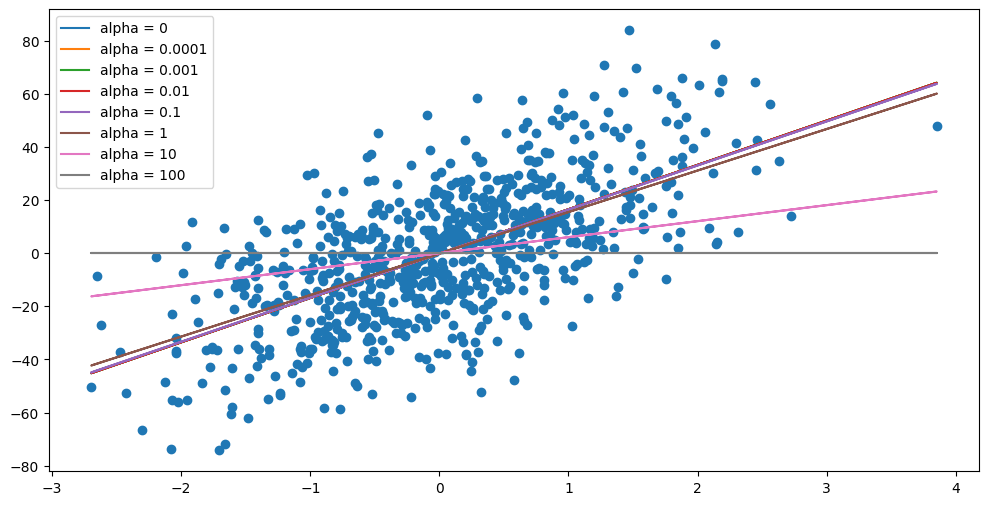

In [14]:
alphas = [0, 0.0001, 0.001, 0.01, 0.1, 1, 10, 100]
plt.figure(figsize= (12, 6))
plt.scatter(X_train, y_train)
for i in alphas:
    ls = Lasso(alpha= i)
    ls.fit(X_train, y_train)
    plt.plot(X_train, ls.predict(X_train), label = (f'alpha = {i}'))
plt.legend()
plt.show()

In [15]:
from sklearn.model_selection import GridSearchCV

In [16]:
params = {'alpha': [0, 0.0001, 0.001, 0.01, 0.1, 1, 10, 100]}

In [17]:
ls = Lasso()
grid = GridSearchCV(estimator= ls, param_grid= params, scoring= 'r2', cv= 5)

In [18]:
grid.fit(X_train, y_train)

C:\Users\gpava\anaconda3\Lib\site-packages\sklearn\base.py:1365: UserWarning: With alpha=0, this algorithm does not converge well. You are advised to use the LinearRegression estimator
  return fit_method(estimator, *args, **kwargs)
C:\Users\gpava\anaconda3\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:695: UserWarning: Coordinate descent with no regularization may lead to unexpected results and is discouraged.
  model = cd_fast.enet_coordinate_descent(
C:\Users\gpava\anaconda3\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.242e+05, tolerance: 4.247e+01
Linear regression models with a zero l1 penalization strength are more efficiently fitted using one of the solvers implemented in sklearn.linear_model.Ridge/RidgeCV instead.
  model = cd_fast.enet_coordinate_descent(


,estimator,Lasso()
,param_grid,"{'alpha': [0, 0.0001, ...]}"
,scoring,'r2'
,n_jobs,None
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,alpha,0.1


In [19]:
df = pd.DataFrame(data= grid.cv_results_)

In [21]:
df[['param_alpha', 'mean_test_score', 'rank_test_score']]

,param_alpha,mean_test_score,rank_test_score
0,0.0000,0.387294,5
1,0.0001,0.387294,4
2,0.0010,0.387295,3
3,0.0100,0.387301,2
4,0.1000,0.387344,1
5,1.0000,0.386237,6
6,10.0000,0.221435,7
7,100.0000,-0.022624,8


In [22]:
# now doing on polynomial data

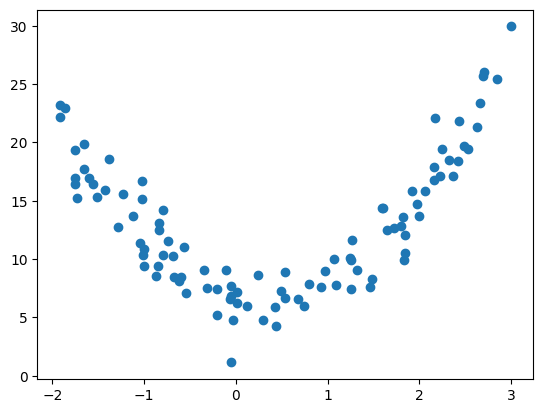

In [35]:
X1 = 5 * np.random.rand(100, 1) - 2
X2 = 3 * X1**2 - 2 * X1 + 7 + 2 * np.random.randn(100, 1)
plt.scatter(X1, X2)
plt.show()

In [36]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import Pipeline

In [37]:
def get_preds(X1, X2, alpha):
    model = Pipeline(
                    [('poly_feats', PolynomialFeatures(degree= 16)),
                      ('lasso', Lasso(alpha))
                    ]
    )
    model.fit(X1, X2)
    return model.predict(X1)

C:\Users\gpava\anaconda3\Lib\site-packages\sklearn\base.py:1365: UserWarning: With alpha=0, this algorithm does not converge well. You are advised to use the LinearRegression estimator
  return fit_method(estimator, *args, **kwargs)
C:\Users\gpava\anaconda3\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:695: UserWarning: Coordinate descent with no regularization may lead to unexpected results and is discouraged.
  model = cd_fast.enet_coordinate_descent(
C:\Users\gpava\anaconda3\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.702e+02, tolerance: 3.337e-01
Linear regression models with a zero l1 penalization strength are more efficiently fitted using one of the solvers implemented in sklearn.linear_model.Ridge/RidgeCV instead.
  model = cd_fast.enet_coordinate_descent(


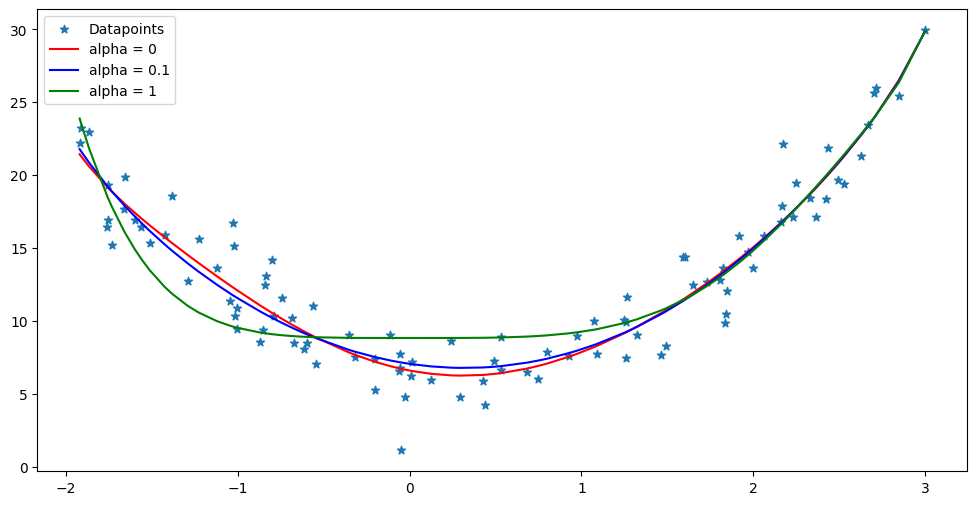

In [38]:
alphas = [0, 0.1, 1]
colors = ['r', 'b', 'g']
plt.figure(figsize= (12, 6))
plt.scatter(X1, X2, marker= '*', label = 'Datapoints')
for alpha, color in zip(alphas, colors):
    preds = get_preds(X1, X2, alpha)
    plt.plot(sorted(X1[:, 0]), preds[np.argsort(X1[:, 0])], color = color, label = f'alpha = {alpha}')
plt.legend()
plt.show()